
# Machine Learning Assignment 2

## Comparison of Classification Algorithms

Dataset: Adult Income Dataset

Objective:
To compare five classification algorithms for
predicting whether a person's annual income
exceeds $50,000.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

%pip install scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 120.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 111.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [12]:

file_path = "/home/cloud/Downloads/adult_dataset/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education-num", "marital-status", "occupation",
    "relationship", "race", "sex", "capital-gain",
    "capital-loss", "hours-per-week", "native-country",
    "income"
]

df = pd.read_csv(
    file_path,
    header=None,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [10]:

import os
import urllib.request

folder_path = "/home/cloud/Downloads/adult_dataset"

os.makedirs(folder_path, exist_ok=True)

file_path = os.path.join(folder_path, "adult.data")

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File location:", file_path)


Dataset downloaded successfully!
File location: /home/cloud/Downloads/adult_dataset/adult.data



I checked the dataset to understand the data types,
missing values and distribution of income categories.

This will help me decide how to prepare the data
before training the classification models.


In [16]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nIncome Category Distribution:")
print(df["income"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Missing Values:
age                  0
workclass         1836
fnlwgt   

The dataset contains numerical and categorical
features. I will separate the input features from
the target variable before preparing the data
for machine learning.

The target variable is income, where:
- 0 represents income <= $50K
  
- 1 represents income > $50K

In [19]:

# Separate input features and target variable

X = df.drop("income", axis=1)

y = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Input features shape: (32561, 14)
Target shape: (32561,)

Target distribution:
income
0    24720
1     7841
Name: count, dtype: int64


I divided the dataset into 80% training data and
20% testing data.

The training data will be used to train the models,
while the testing data will be used to evaluate
their performance on unseen records.

I used stratified splitting to maintain a similar
income category distribution in both datasets.

In [26]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (26048, 14)
Testing features: (6513, 14)
Training target: (26048,)
Testing target: (6513,)


Data Preprocessing

In [29]:

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [31]:

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


Machine Learning Model Implementation

Model 1: Logistic Regression

In [34]:

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


Logistic Regression Predictions

In [37]:

y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 predicted values:")
print(y_pred_logistic[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)


Predictions completed successfully!

First 10 predicted values:
[0 0 1 1 0 0 0 1 0 0]

First 10 actual values:
[0 0 1 1 0 0 0 0 0 0]


Logistic Regression Evaluation

In [40]:

accuracy_lr = accuracy_score(y_test, y_pred_logistic)
auc_lr = roc_auc_score(y_test, y_prob_logistic)
precision_lr = precision_score(y_test, y_pred_logistic)
recall_lr = recall_score(y_test, y_pred_logistic)
f1_lr = f1_score(y_test, y_pred_logistic)
mcc_lr = matthews_corrcoef(y_test, y_pred_logistic)

print("Logistic Regression Evaluation Results")
print("--------------------------------------")
print("Accuracy :", round(accuracy_lr, 4))
print("AUC      :", round(auc_lr, 4))
print("Precision:", round(precision_lr, 4))
print("Recall   :", round(recall_lr, 4))
print("F1 Score :", round(f1_lr, 4))
print("MCC      :", round(mcc_lr, 4))


Logistic Regression Evaluation Results
--------------------------------------
Accuracy : 0.8558
AUC      : 0.9078
Precision: 0.7406
Recall   : 0.6173
F1 Score : 0.6734
MCC      : 0.5858


In [42]:

results = []

results.append({
    "ML Model Name": "Logistic Regression",
    "Accuracy": accuracy_lr,
    "AUC": auc_lr,
    "Precision": precision_lr,
    "Recall": recall_lr,
    "F1": f1_lr,
    "MCC": mcc_lr
})

print("Logistic Regression results saved!")


Logistic Regression results saved!


Model 2: Decision Tree Classifier

In [45]:

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


Decision Tree Evaluation

In [48]:

y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

accuracy_dt = accuracy_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
mcc_dt = matthews_corrcoef(y_test, y_pred_dt)

print("Decision Tree Evaluation Results")
print("--------------------------------")
print("Accuracy :", round(accuracy_dt, 4))
print("AUC      :", round(auc_dt, 4))
print("Precision:", round(precision_dt, 4))
print("Recall   :", round(recall_dt, 4))
print("F1 Score :", round(f1_dt, 4))
print("MCC      :", round(mcc_dt, 4))


Decision Tree Evaluation Results
--------------------------------
Accuracy : 0.8572
AUC      : 0.9022
Precision: 0.7206
Recall   : 0.6645
F1 Score : 0.6914
MCC      : 0.5996


In [50]:

results.append({
    "ML Model Name": "Decision Tree",
    "Accuracy": accuracy_dt,
    "AUC": auc_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1": f1_dt,
    "MCC": mcc_dt
})

print("Decision Tree results saved!")
print("Total models evaluated:", len(results))


Decision Tree results saved!
Total models evaluated: 2


Model 3: K-Nearest Neighbors (KNN)


In [55]:

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


KNN Model Evaluation

In [58]:

y_pred_knn = knn_model.predict(X_test)

y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

accuracy_knn = accuracy_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
mcc_knn = matthews_corrcoef(y_test, y_pred_knn)

print("KNN Evaluation Results")
print("----------------------")
print("Accuracy :", round(accuracy_knn, 4))
print("AUC      :", round(auc_knn, 4))
print("Precision:", round(precision_knn, 4))
print("Recall   :", round(recall_knn, 4))
print("F1 Score :", round(f1_knn, 4))
print("MCC      :", round(mcc_knn, 4))


KNN Evaluation Results
----------------------
Accuracy : 0.8366
AUC      : 0.8679
Precision: 0.6775
Recall   : 0.6135
F1 Score : 0.6439
MCC      : 0.5394


In [60]:

results.append({
    "ML Model Name": "KNN",
    "Accuracy": accuracy_knn,
    "AUC": auc_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1": f1_knn,
    "MCC": mcc_knn
})

print("KNN results saved!")
print("Total models evaluated:", len(results))


KNN results saved!
Total models evaluated: 3


Model 4: Gaussian Naive Bayes

In [63]:

nb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes trained successfully!")


Gaussian Naive Bayes trained successfully!


Gaussian Naive Bayes Evaluation

In [66]:

y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

accuracy_nb = accuracy_score(y_test, y_pred_nb)
auc_nb = roc_auc_score(y_test, y_prob_nb)
precision_nb = precision_score(y_test, y_pred_nb)
recall_nb = recall_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)
mcc_nb = matthews_corrcoef(y_test, y_pred_nb)

print("Gaussian Naive Bayes Evaluation Results")
print("--------------------------------------")
print("Accuracy :", round(accuracy_nb, 4))
print("AUC      :", round(auc_nb, 4))
print("Precision:", round(precision_nb, 4))
print("Recall   :", round(recall_nb, 4))
print("F1 Score :", round(f1_nb, 4))
print("MCC      :", round(mcc_nb, 4))


Gaussian Naive Bayes Evaluation Results
--------------------------------------
Accuracy : 0.5382
AUC      : 0.7495
Precision: 0.3374
Recall   : 0.9528
F1 Score : 0.4983
MCC      : 0.3294


In [68]:

results.append({
    "ML Model Name": "Gaussian Naive Bayes",
    "Accuracy": accuracy_nb,
    "AUC": auc_nb,
    "Precision": precision_nb,
    "Recall": recall_nb,
    "F1": f1_nb,
    "MCC": mcc_nb
})

print("Gaussian Naive Bayes results saved!")
print("Total models evaluated:", len(results))


Gaussian Naive Bayes results saved!
Total models evaluated: 4


Support Vector Machine (SVM)

In [71]:

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM model trained successfully!


SVM Model Evaluation

In [74]:

y_pred_svm = svm_model.predict(X_test)

y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

accuracy_svm = accuracy_score(y_test, y_pred_svm)
auc_svm = roc_auc_score(y_test, y_prob_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
mcc_svm = matthews_corrcoef(y_test, y_pred_svm)

print("SVM Evaluation Results")
print("----------------------")
print("Accuracy :", round(accuracy_svm, 4))
print("AUC      :", round(auc_svm, 4))
print("Precision:", round(precision_svm, 4))
print("Recall   :", round(recall_svm, 4))
print("F1 Score :", round(f1_svm, 4))
print("MCC      :", round(mcc_svm, 4))


SVM Evaluation Results
----------------------
Accuracy : 0.8597
AUC      : 0.9056
Precision: 0.7654
Recall   : 0.6014
F1 Score : 0.6736
MCC      : 0.5927


In [76]:

results.append({
    "ML Model Name": "SVM",
    "Accuracy": accuracy_svm,
    "AUC": auc_svm,
    "Precision": precision_svm,
    "Recall": recall_svm,
    "F1": f1_svm,
    "MCC": mcc_svm
})

print("SVM results saved!")
print("Total models evaluated:", len(results))


SVM results saved!
Total models evaluated: 5


Final Comparison of Machine Learning Models

In [79]:

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.round(4)

print("Final Model Comparison Table")
display(comparison_df)


Final Model Comparison Table


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8558,0.9078,0.7406,0.6173,0.6734,0.5858
1,Decision Tree,0.8572,0.9022,0.7206,0.6645,0.6914,0.5996
2,KNN,0.8366,0.8679,0.6775,0.6135,0.6439,0.5394
3,Gaussian Naive Bayes,0.5382,0.7495,0.3374,0.9528,0.4983,0.3294
4,SVM,0.8597,0.9056,0.7654,0.6014,0.6736,0.5927


Best Model Selection

In [82]:

best_model_row = comparison_df.loc[
    comparison_df["F1"].idxmax()
]

best_model_name = best_model_row["ML Model Name"]

print("Best Model:", best_model_name)
print("F1 Score:", best_model_row["F1"])
print("Accuracy:", best_model_row["Accuracy"])
print("AUC:", best_model_row["AUC"])
print("MCC:", best_model_row["MCC"])


Best Model: Decision Tree
F1 Score: 0.6914
Accuracy: 0.8572
AUC: 0.9022
MCC: 0.5996


F1 Score Comparison of Machine Learning Models

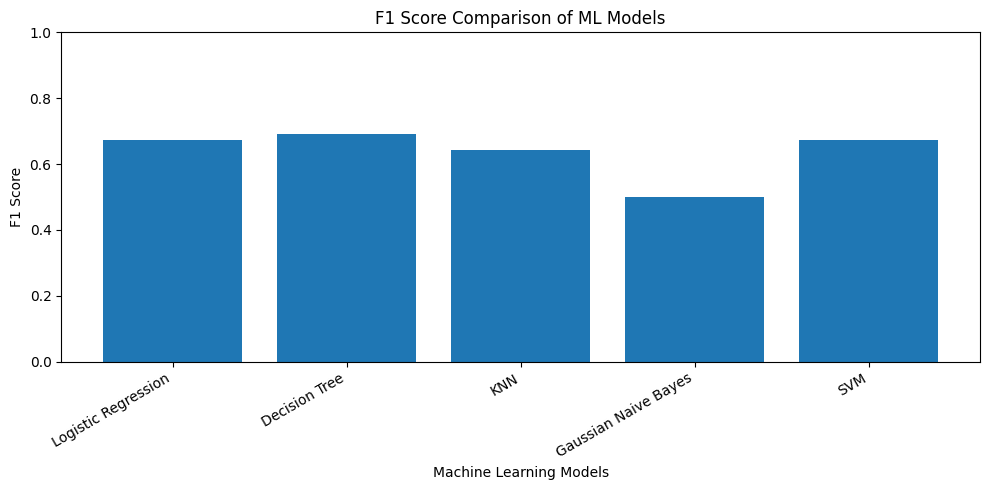

In [85]:

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["ML Model Name"],
    comparison_df["F1"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.title("F1 Score Comparison of ML Models")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


Saving the Best Machine Learning Model

In [88]:

import joblib

best_model = decision_tree_model

joblib.dump(
    best_model,
    "best_decision_tree_model.pkl"
)

print("Best model saved successfully!")
print("Model Name: Decision Tree")
print("File Name: best_decision_tree_model.pkl")


Best model saved successfully!
Model Name: Decision Tree
File Name: best_decision_tree_model.pkl


Verification of the Saved Model


In [91]:

loaded_model = joblib.load("best_decision_tree_model.pkl")

loaded_predictions = loaded_model.predict(X_test)

original_predictions = decision_tree_model.predict(X_test)

print("Saved model loaded successfully!")

print(
    "Predictions match:",
    np.array_equal(loaded_predictions, original_predictions)
)

print(
    "Loaded Model Accuracy:",
    round(accuracy_score(y_test, loaded_predictions), 4)
)


Saved model loaded successfully!
Predictions match: True
Loaded Model Accuracy: 0.8572


In [94]:

import os
import joblib

os.makedirs("model", exist_ok=True)

models = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

for name, model in models.items():
    joblib.dump(model, f"model/{name}.pkl")
    print(f"{name} saved successfully!")

print("Total models saved:", len(models))


logistic_regression saved successfully!
decision_tree saved successfully!
knn saved successfully!
naive_bayes saved successfully!
svm saved successfully!
Total models saved: 5


In [96]:

import os

model_files = os.listdir("model")

print("Files inside model folder:")

for file in sorted(model_files):
    print(file)

print("\nTotal files:", len(model_files))


Files inside model folder:
decision_tree.pkl
knn.pkl
logistic_regression.pkl
naive_bayes.pkl
svm.pkl

Total files: 5


In [98]:

test_data = X_test.head(100).copy()

test_data.to_csv("test_data.csv", index=False)

print("test_data.csv created successfully!")
print("Number of rows:", test_data.shape[0])
print("Number of columns:", test_data.shape[1])

display(test_data.head())


test_data.csv created successfully!
Number of rows: 100
Number of columns: 14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
9009,31,Self-emp-inc,117963,Doctorate,16,Never-married,Prof-specialty,Own-child,White,Male,0,0,40,United-States
25134,20,NaN,201490,Some-college,10,Never-married,NaN,Own-child,White,Male,0,0,40,United-States
16682,78,Self-emp-inc,385242,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,9386,0,45,United-States
27044,32,Private,164197,Bachelors,13,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,44,United-States
3302,61,Private,92691,HS-grad,9,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,3,United-States


In [100]:

import importlib.util

if importlib.util.find_spec("streamlit") is not None:
    print("Streamlit is already installed!")
else:
    print("Streamlit is not installed.")


Streamlit is not installed.


In [102]:

%pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 138.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 115.5 MB/s eta 0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.11.0
    Uninstalling typing_extensions-4.11.0:
      Successfully uninstalled typing_extensions-4.11.0
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.3
    Uninstalling protobuf-4.25.3:
      Successfully uninstalled protobuf-4.25.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.17.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 7.3

In [104]:

import streamlit as st

print("Streamlit imported successfully!")
print("Streamlit version:", st.__version__)


Streamlit imported successfully!
Streamlit version: 1.67.0


In [106]:

app_code = '''
import streamlit as st
import pandas as pd
import joblib
import os

st.title("Adult Income Prediction")
st.write("Machine Learning Assignment 2")

model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "KNN": "knn.pkl",
    "Gaussian Naive Bayes": "naive_bayes.pkl",
    "SVM": "svm.pkl"
}

selected_model = st.selectbox(
    "Select Machine Learning Model",
    list(model_files.keys())
)

uploaded_file = st.file_uploader(
    "Upload CSV file",
    type=["csv"]
)

if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)

    st.write("Uploaded Data")
    st.dataframe(data.head())

    if st.button("Predict"):
        model_path = os.path.join(
            "model", model_files[selected_model]
        )

        model = joblib.load(model_path)

        predictions = model.predict(data)

        result = data.copy()
        result["Predicted Income"] = predictions

        st.write("Prediction Results")
        st.dataframe(result)

        csv = result.to_csv(index=False)

        st.download_button(
            "Download Predictions",
            csv,
            "predictions.csv",
            "text/csv"
        )
'''

with open("app.py", "w") as file:
    file.write(app_code)

print("app.py created successfully!")


app.py created successfully!


In [112]:
!streamlit run app.py


      👋 Welcome to Streamlit!

      If you'd like to receive helpful onboarding emails, news, offers, promotions,
      and the occasional swag, please enter your email address below. Otherwise,
      leave this field blank.

      Email:  ^C
2026-11-10 20:26:18.770 


In [114]:
import os

print("Notebook working directory:", os.getcwd())
print("App file exists:", os.path.exists("app.py"))

Notebook working directory: /home/s2026ak05410/workspace
App file exists: True


In [116]:
import os

print("Files in workspace:")
for item in sorted(os.listdir(".")):
    print(item)

print("\nSaved ML Models:")
for item in sorted(os.listdir("model")):
    print(item)

Files in workspace:
.Trash-1000
.ipynb_checkpoints
2026ak05410.pdf
Assignment_2_Optimization_MFML.ipynb
ML_Assignment_2_Classification.ipynb
app.py
best_decision_tree_model.pkl
model
test_data.csv

Saved ML Models:
decision_tree.pkl
knn.pkl
logistic_regression.pkl
naive_bayes.pkl
svm.pkl


In [ ]:

import os
import zipfile

zip_name = "ML_Assignment_2_Final_Submission.zip"

files_to_include = [
    "ML_Assignment_2_Classification.ipynb",
    "app.py",
    "test_data.csv"
]

model_folder = "model"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_include:
        if os.path.isfile(file):
            zipf.write(file)
            print("Added:", file)
        else:
            print("MISSING:", file)

    for root, dirs, files in os.walk(model_folder):
        for file in files:
            if file.endswith(".pkl"):
                file_path = os.path.join(root, file)
                zipf.write(file_path)
                print("Added:", file_path)

print("\nZIP file created:", zip_name)
print("ZIP size:", round(os.path.getsize(zip_name) / 1024, 2), "KB")
